# Figure 4, Panel F

Heatmaps of expression (log2(TPM+1), Z-scored) for IFNg and Dex-inducible genes, -/+ stimulus and -/+ BAFinh pretreatment. Also generate heatmaps showing extent repression of induction by BAFinh (log2FC BAFinh + stim vs stim alone)

*Outputs:* 
- Expression heatmaps: ifn_1h_hm.pdf, ifn_6h_hm.pdf, dex_1h_hm.pdf, dex_6h_hm.pdf
- Log2FC heatmaps: ifn_1h_fc_hm.pdf, ifn_6h_fc_hm.pdf, dex_1h_fc_hm.pdf, dex_6h_fc_hm.pdf

# Setup

In [10]:
# load packages
library(tidyverse)
library(RColorBrewer)
library(pheatmap)
library(gridExtra)
library(here)
here::i_am("figures/Figure4/Panel_F/PanelF_heatmap.ipynb")

theme_set(theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=15)))

dex_col <- "#5791c9"
ifn_col <- "#149e77"

#function to generate heatmap given table of TPMs, list of table rows to plot, and treatment conditions
hm <- function(table, rows, treatments, color, scale="row"){
    temp <- table[rows,]
    names <- colnames(temp)
    condition <-  gsub("_r.*$", "", names) #extract condition (dose + time) as well as dose and time separately
    treatment <- gsub("_.h$", "", condition)
    keep_cols <- which(treatment %in% treatments,)
    temp <- temp[,keep_cols]
    pheatmap(log2(temp+1), cluster_rows=FALSE, cluster_cols=FALSE, color=colorRampPalette(c("white", color))(100), scale=scale , show_rownames=FALSE, cellheight = 1,breaks=seq(-2,2,length.out=100), main=paste("n=", length(rows)))
}

sessionInfo()

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2         gridExtra_2.3      pheatmap_1.0.12    RColorBrewer_1.1-3
 [5] lubridate_1.9.4    forcats_1.0.0      stringr_1.5.1      dplyr_1.1.4       
 [9] purrr_1.0.2        readr_2.1.5        tidyr_1.3.1        tibble_3.2.1      
[13] ggplot2_3.5.2      tidyverse_2.0.0   

loaded 

# Load data

In [20]:
# load sample data (col.data), gene metadata (row.data) and table of TPMs

# TPMs
tpms <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep",
    "VST_abundance_batchCorr.tsv"
  ),
  sep = "\t"
)
# gene-level metadata
row.data <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep",
    "gene_metadata.tsv"
  ),
  sep = "\t"
)

# sample-level metadata
col.data <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep",
    "rsem_metadata.tsv"
  ),
  sep = "\t"
)

#read in DEGs
ifn_1h <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep",
    "IFN_1h_DEGs.tsv"
  ),
  sep = "\t"
)

ifn_6h <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep",
    "IFN_6h_DEGs.tsv"
  ),
  sep = "\t"
)

dex_1h <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep",
    "Dex_1h_DEGs.tsv"
  ),
  sep = "\t"
)

dex_6h <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep",
    "Dex_6h_DEGs.tsv"
  ),
  sep = "\t"
)


# BAFinh -> stimulus vs stimulus alone
brm_ifn_1h <- read.delim(
  here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep", "BAFinh_IFN_1h_DEGs.tsv"),
  sep = "\t"
)

brm_ifn_6h <- read.delim(
  here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep", "BAFinh_IFN_6h_DEGs.tsv"),
  sep = "\t"
)

brm_dex_1h <- read.delim(
  here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep", "BAFinh_Dex_1h_DEGs.tsv"),
  sep = "\t"
)

brm_dex_6h <- read.delim(
  here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep", "BAFinh_Dex_6h_DEGs.tsv"),
  sep = "\t"
)

#PROseq DEG

pro_ifn <- read.delim(
    here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "PROseq", "PRO_DEGs_IFN_Veh.tsv"),
    sep='\t')
pro_ifn <- pro_ifn[match(row.data$gene_id_base, pro_ifn$ENSEMBL_ID),]

pro_bafinh_ifn <- read.delim(
    here("inputs", "DEGs", "GM12878", "BAFinh_stimulus", "PROseq", "PRO_DEGs_BAFinh_IFN_IFN.tsv"),
    sep='\t')
pro_bafinh_ifn <- pro_bafinh_ifn[match(row.data$gene_id_base, pro_bafinh_ifn$ENSEMBL_ID),]

# make data frames of BAFinh+stim vs stim log2FCs for each stimulus (both timepoints)
ifny_fc <- data.frame(
  "fc_1h" = brm_ifn_1h$log2FoldChange,
  "fc_6h" = brm_ifn_6h$log2FoldChange
)

dex_fc <- data.frame(
  "fc_1h" = brm_dex_1h$log2FoldChange,
  "fc_6h" = brm_dex_6h$log2FoldChange
)

# Determine 1h- and 6h-up gene sets and order by induction magnitude (for heatmap plotting)

In [5]:
#define 1h-induced and 6h-induced gene sets

ifn_up_1h <- which((ifn_1h$change == "up" & ifn_6h$change != "up") | (ifn_1h$change == "up" & ifn_6h$change == "up"))
ifn_up_1h_ordered <- (ifn_1h[ifn_up_1h,] %>% mutate(rownum=ifn_up_1h) %>% arrange(desc((log2FoldChange*baseMean)-baseMean)))$rownum

ifn_up_6h <- which(ifn_1h$change != "up" & ifn_6h$change == "up")
ifn_up_6h_ordered <- (ifn_6h[ifn_up_6h,] %>% mutate(rownum=ifn_up_6h)  %>% arrange(desc((log2FoldChange*baseMean)-baseMean)))$rownum

dex_up_1h <- which((dex_1h$change == "up" & dex_6h$change != "up") | (dex_1h$change == "up" & dex_6h$change == "up"))
dex_up_1h_ordered <- (dex_1h[dex_up_1h,] %>% mutate(rownum=dex_up_1h)  %>% arrange(desc((log2FoldChange*baseMean)-baseMean)))$rownum

dex_up_6h <- which(dex_1h$change != "up" & dex_6h$change == "up")
dex_up_6h_ordered <- (dex_6h[dex_up_6h,] %>% mutate(rownum=dex_up_6h)  %>% arrange(desc((log2FoldChange*baseMean)-baseMean)))$rownum

# Generate scaled TPM heatmaps

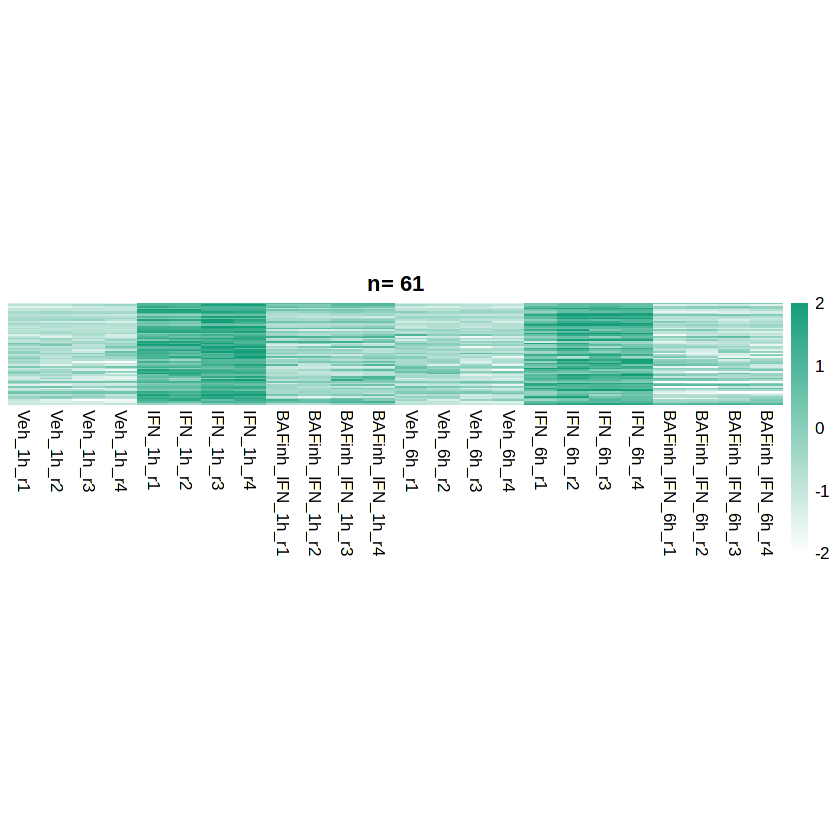

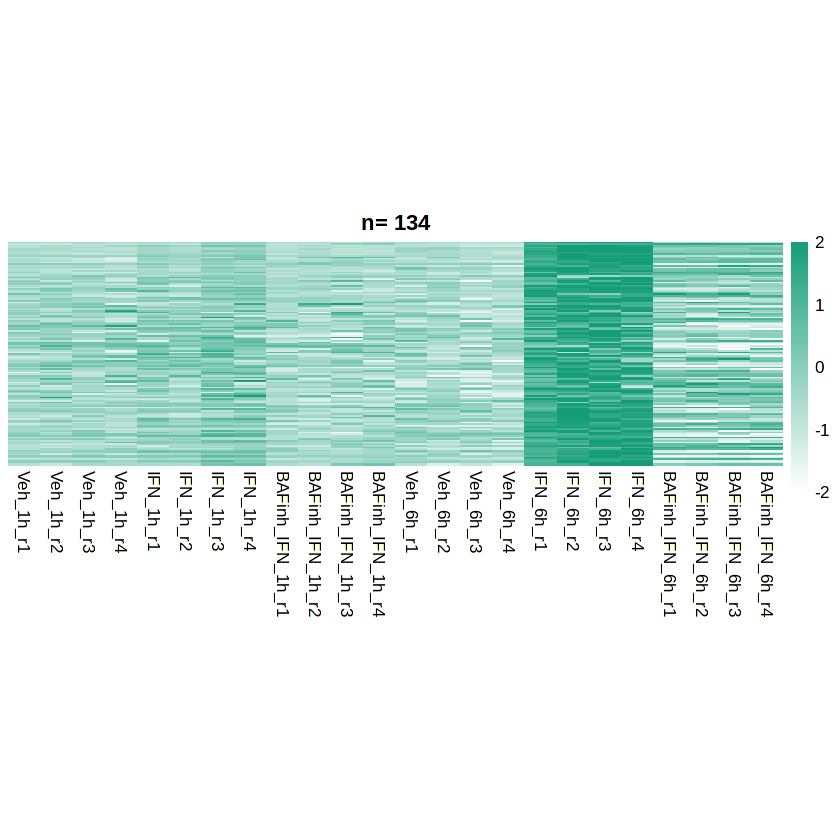

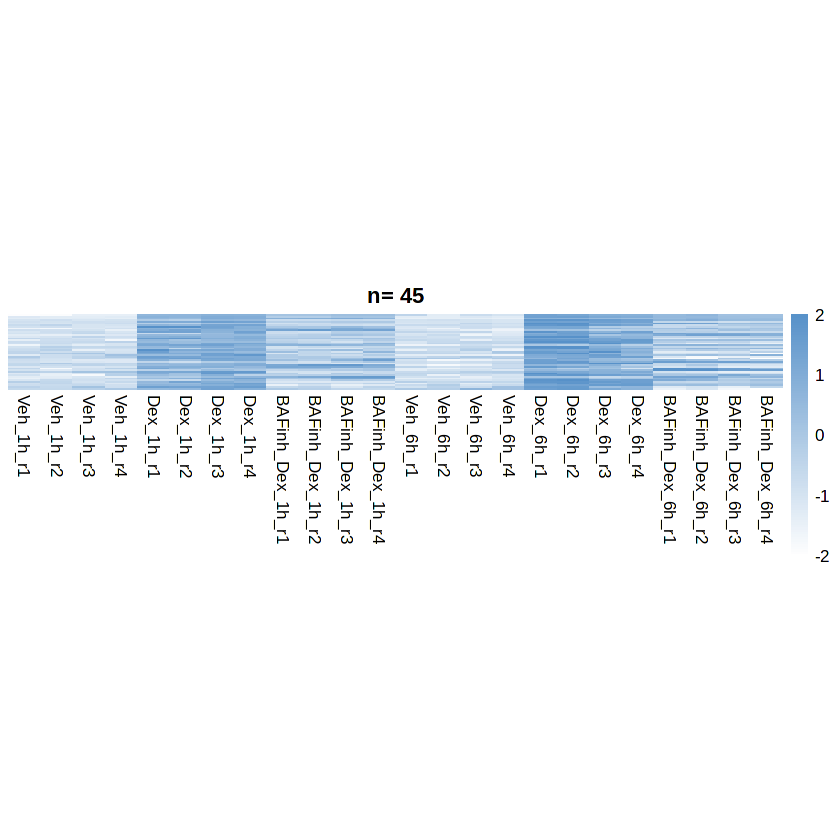

pdf 
  2

pdf 
  2

pdf 
  2

pdf 
  2

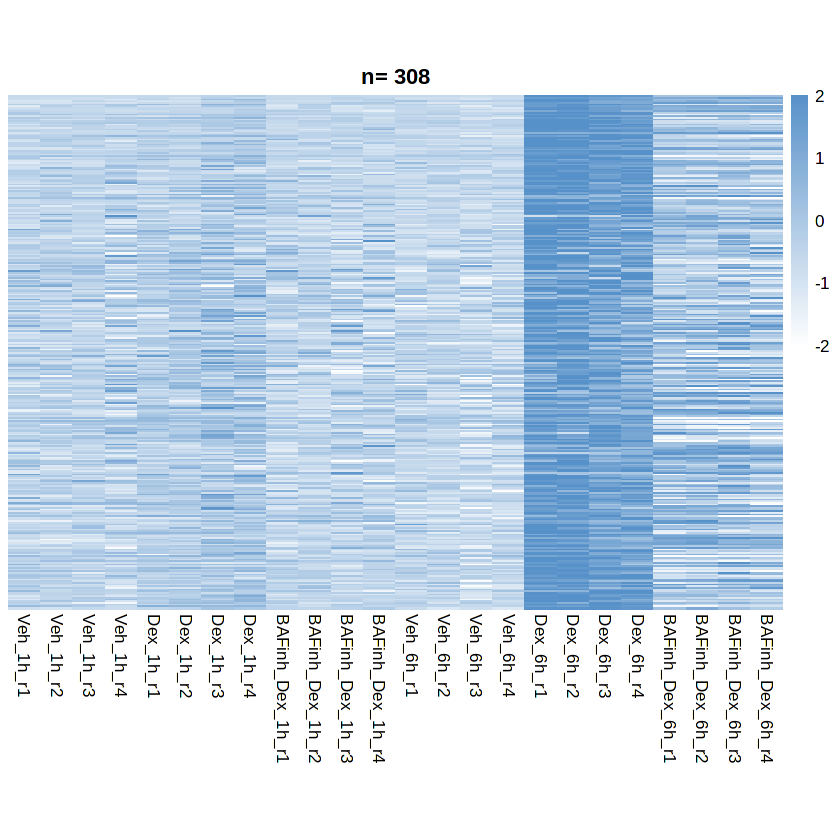

In [11]:

ifn_1h_hm <- hm(tpms,ifn_up_1h_ordered, c("Veh", "IFN", "BAFinh_IFN"), ifn_col, scale="row")
ifn_6h_hm <- hm(tpms,ifn_up_6h_ordered, c("Veh", "IFN","BAFinh_IFN"), ifn_col, scale="row")
dex_1h_hm <- hm(tpms,dex_up_1h_ordered, c("Veh", "Dex","BAFinh_Dex"), dex_col, scale="row")
dex_6h_hm <- hm(tpms,dex_up_6h_ordered, c("Veh", "Dex","BAFinh_Dex"), dex_col, scale="row")

pdf("ifn_1h_hm.pdf", width=2, height=2)
ifn_1h_hm
dev.off()

pdf("ifn_6h_hm.pdf", width=2, height=4)
ifn_6h_hm
dev.off()

pdf("dex_1h_hm.pdf", width=2, height=2)
dex_1h_hm
dev.off()

pdf("dex_6h_hm.pdf", width=2, height=6)
dex_6h_hm
dev.off()

# Generate BAFinh + stim vs stim log2FC heatmaps

In [12]:
cols <- c("navy", "white", "firebrick")
pheatmap(ifny_fc[ifn_up_1h_ordered,], 
         cluster_rows=FALSE, cluster_cols=FALSE,
        color=colorRampPalette(cols)(100), 
         breaks=c(seq(-4,4,length.out=101)),
        show_rownames=FALSE, cellheight=1, 
        filename="ifn_1h_fc_hm.pdf", width=1, height=2)

pheatmap(ifny_fc[ifn_up_6h_ordered,], 
         cluster_rows=FALSE, cluster_cols=FALSE,
        color=colorRampPalette(cols)(100), 
         breaks=c(seq(-4,4,length.out=101)),
         show_rownames=FALSE, cellheight=1,
         filename="ifn_6h_fc_hm.pdf", width=1, height=4)

pheatmap(dex_fc[dex_up_1h_ordered,], 
         cluster_rows=FALSE, cluster_cols=FALSE,
        color=colorRampPalette(cols)(100), 
         breaks=c(seq(-4,4,length.out=101)),
        show_rownames=FALSE, cellheight=1,
         filename="dex_1h_fc_hm.pdf", width=1, height=2)

pheatmap(dex_fc[dex_up_6h_ordered,], 
         cluster_rows=FALSE, cluster_cols=FALSE,
        color=colorRampPalette(cols)(100), 
         breaks=c(seq(-4,4,length.out=101)),
         show_rownames=FALSE, cellheight=1,
          filename="dex_6h_fc_hm.pdf",width=1, height=6)

In [43]:
# generate PRO-seq IFN and BAFinh+IFN heatmaps
cols <- c("#006CD1", "#FFFFFF", "#994F00")
pheatmap(pro_ifn$log2FoldChange[ifn_up_1h_ordered], 
         cluster_rows=FALSE, cluster_cols=FALSE,
        color=colorRampPalette(cols)(100), 
         breaks=c(seq(-4,4,length.out=101)),
        show_rownames=FALSE, cellheight=1, 
        filename="pro_ifn_1h_fc_hm.pdf", width=1, height=2)

pheatmap(pro_ifn$log2FoldChange[ifn_up_6h_ordered], 
         cluster_rows=FALSE, cluster_cols=FALSE,
        color=colorRampPalette(cols)(100), 
         breaks=c(seq(-4,4,length.out=101)),
         show_rownames=FALSE, cellheight=1,
         filename="pro_ifn_6h_fc_hm.pdf", width=1, height=4)

pheatmap(pro_bafinh_ifn$log2FoldChange[ifn_up_1h_ordered], 
         cluster_rows=FALSE, cluster_cols=FALSE,
        color=colorRampPalette(cols)(100), 
         breaks=c(seq(-4,4,length.out=101)),
        show_rownames=FALSE, cellheight=1, 
        filename="pro_bafinh_ifn_1h_fc_hm.pdf", width=1, height=2)

pheatmap(pro_bafinh_ifn$log2FoldChange[ifn_up_6h_ordered], 
         cluster_rows=FALSE, cluster_cols=FALSE,
        color=colorRampPalette(cols)(100), 
         breaks=c(seq(-4,4,length.out=101)),
         show_rownames=FALSE, cellheight=1,
         filename="pro_bafinh_ifn_6h_fc_hm.pdf", width=1, height=4)

In [19]:
#write out data frame of inducible DEGs

data.frame(ENSEMBL_ID=
            gsub("\\..*$", "", ifn_1h$ENSEMBL_ID),
            gene_symbol=ifn_1h$gene, 
            ifn_ind = ifn_1h$change == "up" | ifn_6h$change=="up",
            dex_ind = dex_1h$change == "up" | dex_6h$change=="up",
            ifn_1h_log2fc = ifn_1h$log2FoldChange,
            ifn_6h_log2fc = ifn_6h$log2FoldChange,
            dex_1h_log2fc = dex_1h$log2FoldChange,
            dex_6h_log2fc = dex_6h$log2FoldChange,
            ifn_ind_brm_rep= (ifn_1h$change == "up" & brm_ifn_1h$change=="down") | (ifn_6h$change == "up" & brm_ifn_6h$change=="down"),
            dex_ind_brm_rep= (dex_1h$change == "up" & brm_dex_1h$change=="down") | (dex_6h$change == "up" & brm_dex_6h$change=="down"),
            brm_ifn_1h_log2fc = brm_ifn_1h$log2FoldChange,
            brm_ifn_6h_log2fc = brm_ifn_6h$log2FoldChange,
            brm_dex_1h_log2fc = brm_dex_1h$log2FoldChange,
            brm_dex_6h_log2fc = brm_dex_6h$log2FoldChange)%>%
    write.table("inducible_genes.tsv", sep='\t', row.names=FALSE, quote=FALSE)
           

In [26]:
sum(ifn_1h$change == "up" | ifn_6h$change =="up")
sum((ifn_1h$change == "up" & brm_ifn_1h$change=="down") | (ifn_6h$change == "up" & brm_ifn_6h$change=="down"))

sum(dex_1h$change == "up" | ifn_6h$change =="up")
sum((dex_1h$change == "up" & brm_ifn_1h$change=="down") | (ifn_6h$change == "up" & brm_ifn_6h$change=="down"))

[1] 155

[1] 91